# 12. Covariance and the limits of linearisation

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 3, 4 and 11, matrix notation

**Reading:** Taylor, ch. 3.11 and 9 · Bevington & Robinson, ch. 3.2 ·
Fornasini, ch. 8.4 · GUM, clause 5.2 · JCGM 101:2008

The propagation law of Chapter 3,
$u_y^2 = \sum_i (\partial f/\partial x_i)^2 u_i^2$, rests on two
assumptions: the inputs are independent, and the model is linear over the
range of the input errors. Research problems violate both routinely. Fit
parameters are correlated with each other, two readings of one instrument
share its calibration error, and quantities such as ratios, exponentials
and inverse powers are strongly nonlinear once relative uncertainties
reach ten per cent or so.

This notebook

1. generalises the propagation law to correlated inputs and to several
   outputs;
2. shows that intermediate results must carry their covariance;
3. derives the second-order correction and uses it to judge when the linear
   law can be trusted;
4. presents Monte Carlo propagation, the method that needs neither
   assumption.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(11)

## 12.1 The general law of propagation

Consider $m$ output quantities $y_k = f_k(x_1, \dots, x_n)$. Collect the
small errors of the inputs in a vector $\delta\boldsymbol{x}$ and those of
the outputs in $\delta\boldsymbol{y}$. To first order,

$$ \delta y_k = \sum_{i=1}^{n} J_{ki}\,\delta x_i , \qquad
   J_{ki} = \frac{\partial f_k}{\partial x_i} , $$

where $\mathsf{J}$ is the Jacobian (sensitivity) matrix. The statistical
information about the inputs is contained in the **covariance matrix**

$$ (\mathsf{C}_x)_{ij} = \langle \delta x_i\,\delta x_j \rangle , $$

whose diagonal elements are the variances $u_i^2$ and whose off-diagonal
elements are the covariances $u_{ij} = \rho_{ij}u_iu_j$, with
$-1 \le \rho_{ij} \le 1$ the correlation coefficient. The same average for
the outputs gives

$$ (\mathsf{C}_y)_{kl} = \langle \delta y_k\,\delta y_l\rangle
 = \sum_{i,j} J_{ki}\,\langle \delta x_i\,\delta x_j\rangle\,J_{lj} , $$

that is,

> $$ \mathsf{C}_y = \mathsf{J}\,\mathsf{C}_x\,\mathsf{J}^{\mathsf T} . $$

This single matrix equation is the whole first-order theory. For one
output it reads

$$ u_y^2 = \sum_i c_i^2 u_i^2 + 2\sum_{i<j} c_i c_j\,\rho_{ij}\,u_i u_j ,
 \qquad c_i = \frac{\partial f}{\partial x_i} , $$

and the second sum is what Chapter 3 left out. It can have either
sign: correlation can increase the output uncertainty or reduce it, and
can even cancel it.

### Sum and difference of two correlated quantities

For $y_\pm = x_1 \pm x_2$ with equal uncertainties $u$,

$$ u_{y_\pm}^2 = 2u^2(1 \pm \rho) . $$

With $\rho = +1$ the difference has no uncertainty at all, and the sum has
twice that of one term (the errors add linearly, not in quadrature). This is
the principle behind every differential measurement: if two readings share
a common error, their difference is free of it. Two temperatures read with
the same thermometer share its calibration offset, so a temperature
*difference* is known better than either temperature. Two total energies
computed with the same functional and settings share most of their
systematic error, which is why energy differences are far more reliable
than absolute energies.

In [2]:
def diff(a, b): return a - b
def summ(a, b): return a + b

u = 0.10
print("  rho    u(a - b)   u(a + b)")
for rho in (-1.0, -0.5, 0.0, 0.5, 0.9, 1.0):
    C = u**2 * np.array([[1, rho], [rho, 1]])
    print(f"{rho:+5.1f}    {ep.propagate(diff, [20.0, 15.0], cov=C)[1]:.4f}     "
          f"{ep.propagate(summ, [20.0, 15.0], cov=C)[1]:.4f}")

  rho    u(a - b)   u(a + b)
 -1.0    0.2000     0.0000
 -0.5    0.1732     0.1000
 +0.0    0.1414     0.1414
 +0.5    0.1000     0.1732
 +0.9    0.0447     0.1949
 +1.0    0.0000     0.2000


### Where does a correlation coefficient come from?

A common situation: two readings $x_1$ and $x_2$ each have an independent
random error with standard deviation $s$ and share a systematic error
(calibration) with standard uncertainty $b$. Then
$\delta x_i = \varepsilon_i + \beta$ with a common $\beta$, and

$$ u_1^2 = u_2^2 = s^2 + b^2 , \qquad u_{12} = \langle(\varepsilon_1 + \beta)(\varepsilon_2 + \beta)\rangle = b^2 ,
 \qquad \rho = \frac{b^2}{s^2 + b^2} . $$

The covariance is simply the variance of the shared part. For the
difference, $u^2 = 2(s^2+b^2) - 2b^2 = 2s^2$: the calibration uncertainty
has dropped out, as it must.

## 12.2 Intermediate results must carry their covariance

Long calculations are done in stages, and the outputs of one stage are the
inputs of the next. Even if the original inputs are independent, the
intermediate quantities are generally not, because they were computed from
the same numbers.

A minimal example: from independent $a \pm u_a$ and $b \pm u_b$ form
$s = a + b$ and $d = a - b$, and then $p = s\,d = a^2 - b^2$. The Jacobian
of the first stage is
$\mathsf J = \begin{pmatrix}1 & 1\\ 1 & -1\end{pmatrix}$, so

$$ \mathsf C_{sd} = \mathsf J \begin{pmatrix}u_a^2 & 0\\ 0 & u_b^2\end{pmatrix} \mathsf J^{\mathsf T}
 = \begin{pmatrix} u_a^2 + u_b^2 & u_a^2 - u_b^2 \\ u_a^2 - u_b^2 & u_a^2 + u_b^2 \end{pmatrix} . $$

Unless $u_a = u_b$, the sum and the difference are correlated.

In [3]:
a, b, u_a, u_b = 5.0, 3.0, 0.20, 0.05

# direct, one stage
p, u_p = ep.propagate(lambda a, b: a**2 - b**2, [a, b], [u_a, u_b])

# two stages, carrying the covariance of (s, d)
sd, C_sd = ep.propagate(lambda a, b: np.array([a + b, a - b]), [a, b], [u_a, u_b])
_, u_p_cov = ep.propagate(lambda s, d: s * d, sd, cov=C_sd)

# two stages, treating s and d as independent
_, u_p_nocov = ep.propagate(lambda s, d: s * d, sd, u=np.sqrt(np.diag(C_sd)))

print(f"covariance matrix of (s, d):\n{C_sd}")
print(f"correlation coefficient: {C_sd[0, 1] / np.sqrt(C_sd[0, 0] * C_sd[1, 1]):+.3f}\n")
print(f"u(p), direct                    : {u_p:.4f}")
print(f"u(p), two stages with covariance: {u_p_cov:.4f}")
print(f"u(p), two stages, cov. ignored  : {u_p_nocov:.4f}   <- wrong")

covariance matrix of (s, d):
[[0.0425 0.0375]
 [0.0375 0.0425]]
correlation coefficient: +0.882

u(p), direct                    : 2.0224
u(p), two stages with covariance: 2.0224
u(p), two stages, cov. ignored  : 1.7000   <- wrong


Carried through with its covariance, the staged calculation reproduces the
direct one exactly. Without it, the answer is too small by 16 % here, and it can
be wrong by orders of magnitude when the correlation is strong (the
Arrhenius example [Chapter 22](../part5_examples/22_arrhenius_activation_energy.ipynb)
is such a case). The practical rules are:

* propagate from the *original, independent* inputs in one step whenever
  possible;
* when intermediate results are published or passed on, give their
  covariance matrix, not only their standard uncertainties.

## 12.3 Beyond first order

The linear law keeps only the tangent to $f$. To see what is neglected,
carry the expansion one order further. For one input with error $\delta x$
of zero mean and variance $u^2$,

$$ y = f(x) + f'\,\delta x + \tfrac12 f''\,\delta x^2 + \dots $$

**A shift of the mean.** Averaging,

$$ \langle y\rangle = f(x) + \tfrac12 f''(x)\,u^2 + \dots $$

The mean of the output is *not* the function of the mean input. A curved
function converts symmetric scatter of $x$ into a bias of $y$. For several
inputs the correction is $\tfrac12\sum_{ij} H_{ij}(\mathsf C_x)_{ij}$ with
$H_{ij} = \partial^2 f/\partial x_i\partial x_j$ the Hessian.

**A correction to the variance.** For a normally distributed $\delta x$
(so that $\langle\delta x^3\rangle = 0$ and $\langle\delta x^4\rangle = 3u^4$),

$$ \operatorname{var}(y) = f'^2u^2 + \tfrac12 f''^2u^4 + \dots $$

**A criterion.** Comparing the two terms of the variance, the linear law is
adequate when

$$ \left|\frac{f''(x)\,u}{f'(x)}\right| \ll 1 , $$

in words: when the slope of $f$ changes little over a distance $u$. For a
power law $f = x^n$ the left-hand side is $|n-1|\,u/x$, so the criterion is
a statement about the *relative* uncertainty. At a relative uncertainty of
1 % the linear law is excellent for any reasonable exponent; at 30 % it is
not, as we shall see.

Three instructive cases:

| Model | Linear law | What actually happens |
|---|---|---|
| $y = e^{x}$, $x \sim N(\mu, \sigma^2)$ | $y = e^\mu$, $u_y = e^\mu\sigma$ | log-normal: mean $e^{\mu + \sigma^2/2}$, skewed to the right |
| $y = x^2$ at $x = 0 \pm \sigma$ | $u_y = 0$ | $\langle y\rangle = \sigma^2$, standard deviation $\sqrt2\,\sigma^2$ |
| $y = a/b$ with $u_b/b = 0.3$ | symmetric normal | heavy tails; mean and variance do not exist |

The second case is the extreme one: at a stationary point the first
derivative vanishes and the linear law returns zero, which is plainly
wrong. It occurs in practice whenever a quantity is measured near an
optimum, or when a squared amplitude is estimated from a noisy signal that
is consistent with zero.

## 12.4 Monte Carlo propagation

The general solution is to give up the expansion altogether and propagate
the *distributions* instead of their widths. The recipe (GUM Supplement 1)
is short:

1. assign a probability distribution to every input (normal, rectangular,
   or a joint normal with a covariance matrix);
2. draw $M$ random sets of inputs;
3. evaluate the model for each set;
4. summarise the $M$ outputs: mean or median, standard deviation, and a
   probability interval from the percentiles.

No derivatives are needed, nonlinearity and correlation are handled
automatically, and the output distribution is obtained in full, including
its asymmetry. The cost is $M$ evaluations of the model. The statistical
error of the result is easy to state: the standard deviation obtained from
$M$ samples has a relative uncertainty of about $1/\sqrt{2M}$ (Section
4.3), so $M = 10^5$ fixes it to 0.2 %, which is more than
enough for any uncertainty statement.

The figure compares the linear law with Monte Carlo for the cases above.

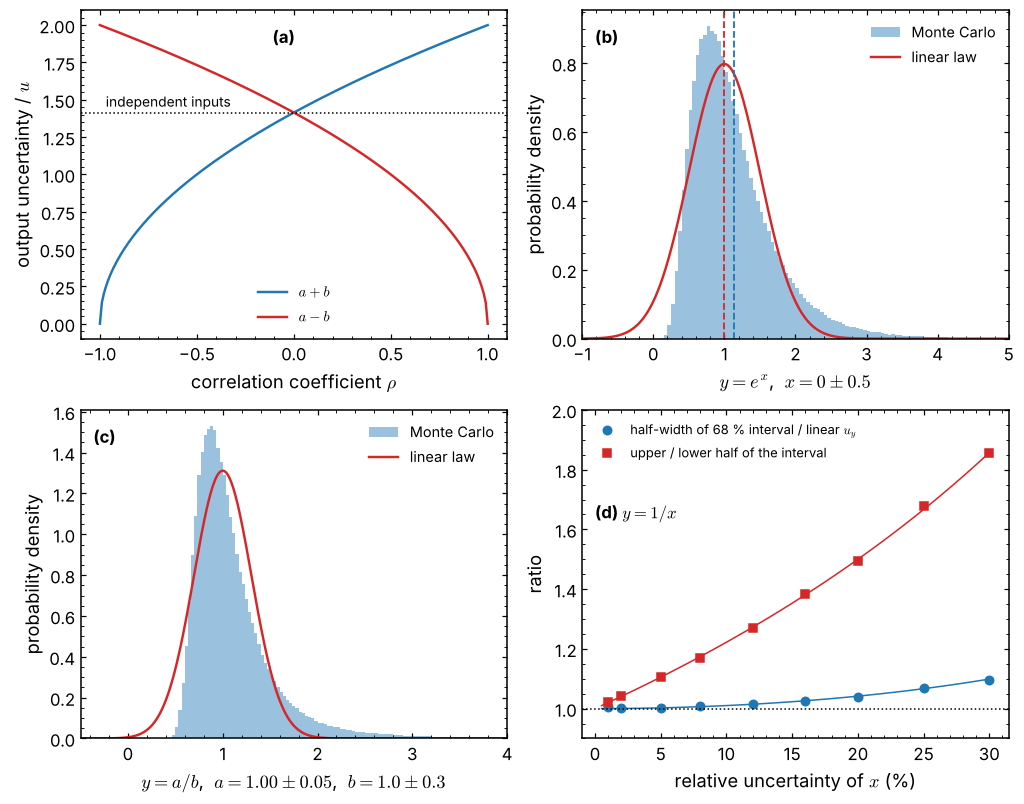

In [4]:
M = 400_000
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

def gauss(g, m, s):
    return np.exp(-0.5 * ((g - m) / s)**2) / (s * np.sqrt(2 * np.pi))

# (a) sum and difference against the correlation coefficient
ax = axes[0, 0]
r = np.linspace(-1, 1, 201)
ax.plot(r, np.sqrt(2 * (1 + r)), "C0", label="$a+b$")
ax.plot(r, np.sqrt(2 * (1 - r)), "C3", label="$a-b$")
ax.axhline(np.sqrt(2), color="k", ls=":", lw=1)
ax.text(-0.97, np.sqrt(2) + 0.04, "independent inputs", fontsize=9)
ax.set_xlabel(r"correlation coefficient $\rho$"); ax.set_ylabel("output uncertainty / $u$")
ax.legend(loc="lower center"); ep.panel_label(ax, "(a)", x=0.45)

# (b) exponential of a normal variable
ax = axes[0, 1]
mu, sig = 0.0, 0.5
y = ep.monte_carlo(np.exp, [mu], [sig], n=M, rng=rng)
g = np.linspace(-1, 5, 400)
ax.hist(y, bins=np.linspace(-1, 5, 121), density=True, color="C0", alpha=0.45, label="Monte Carlo")
ax.plot(g, gauss(g, np.exp(mu), np.exp(mu) * sig), "C3", label="linear law")
ax.axvline(y.mean(), color="C0", ls="--", lw=1.2)
ax.axvline(np.exp(mu), color="C3", ls="--", lw=1.2)
ax.set_xlabel(r"$y = e^{x}$,  $x = 0 \pm 0.5$"); ax.set_ylabel("probability density")
ax.set_xlim(-1, 5); ax.legend(); ep.panel_label(ax, "(b)")
mc_exp = ep.summarize(y)

# (c) ratio with a poorly known denominator
ax = axes[1, 0]
ratio = lambda a, b: a / b
x_r, u_r = [1.0, 1.0], [0.05, 0.30]
yr = ep.monte_carlo(ratio, x_r, u_r, n=M, rng=rng)
y0, u0 = ep.propagate(ratio, x_r, u_r)
g = np.linspace(-0.5, 4, 400)
ax.hist(yr, bins=np.linspace(-0.5, 4, 136), density=True, color="C0", alpha=0.45, label="Monte Carlo")
ax.plot(g, gauss(g, y0, u0), "C3", label="linear law")
ax.set_xlabel(r"$y = a/b$,  $a = 1.00 \pm 0.05$,  $b = 1.0 \pm 0.3$"); ax.set_ylabel("probability density")
ax.set_xlim(-0.5, 4); ax.legend(); ep.panel_label(ax, "(c)")
mc_ratio = ep.summarize(yr)

# (d) how the linear law degrades with the relative uncertainty, y = 1/x
ax = axes[1, 1]
rel = np.array([0.01, 0.02, 0.05, 0.08, 0.12, 0.16, 0.20, 0.25, 0.30])
hw, asym = [], []
for q in rel:
    s = ep.summarize(ep.monte_carlo(lambda x: 1 / x, [1.0], [q], n=M, rng=rng))
    hw.append(0.5 * (s["high"] - s["low"]) / q)          # the linear law predicts 1
    asym.append((s["high"] - s["median"]) / (s["median"] - s["low"]))
qq = np.linspace(0.005, 0.30, 100)
ax.plot(qq * 100, 1 / (1 - qq**2), "C0", lw=1)
ax.plot(qq * 100, (1 + qq) / (1 - qq), "C3", lw=1)
ax.plot(rel * 100, hw, "o", color="C0", label="half-width of 68 % interval / linear $u_y$")
ax.plot(rel * 100, asym, "s", color="C3", label="upper / lower half of the interval")
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel("relative uncertainty of $x$ (%)"); ax.set_ylabel("ratio")
ax.set_ylim(0.9, 2.0); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(d) $y = 1/x$", y=0.72)
plt.show()

In [5]:
print("y = exp(x), x = 0 +/- 0.5")
print(f"  linear law : {np.exp(mu):.3f} +/- {np.exp(mu) * sig:.3f}")
print(f"  Monte Carlo: mean {mc_exp['mean']:.3f} (exact {np.exp(sig**2 / 2):.3f}), "
      f"median {mc_exp['median']:.3f}, 68 % interval [{mc_exp['low']:.3f}, {mc_exp['high']:.3f}]")
print(f"  second-order estimate of the mean: {np.exp(mu) * (1 + sig**2 / 2):.3f}")
print("\ny = a / b, b = 1.0 +/- 0.3")
print(f"  linear law : {y0:.3f} +/- {u0:.3f}")
print(f"  Monte Carlo: median {mc_ratio['median']:.3f}, 68 % interval "
      f"[{mc_ratio['low']:.3f}, {mc_ratio['high']:.3f}],  sample std {mc_ratio['std']:.1f} (meaningless)")
print(f"  fraction of samples outside y0 +/- 3 u0: {np.mean(np.abs(yr - y0) > 3 * u0):.4f}  (normal: 0.0027)")

y = exp(x), x = 0 +/- 0.5
  linear law : 1.000 +/- 0.500
  Monte Carlo: mean 1.133 (exact 1.133), median 0.999, 68 % interval [0.607, 1.648]
  second-order estimate of the mean: 1.125

y = a / b, b = 1.0 +/- 0.3
  linear law : 1.000 +/- 0.304
  Monte Carlo: median 0.999, 68 % interval [0.764, 1.430],  sample std 6.4 (meaningless)
  fraction of samples outside y0 +/- 3 u0: 0.0562  (normal: 0.0027)


**Panel (a)** is the formula $u^2 = 2u_x^2(1\pm\rho)$ of Section 12.1.

**Panel (b).** The output is log-normal. Its mean (blue dashed line) lies
13 % above $e^\mu$ (red dashed line), as the second-order formula predicts
to within a per cent, and the distribution is skewed. The honest summary
is an asymmetric interval. Equivalently, one reports $\ln y$, which *is*
normal: $\ln y = 0.0 \pm 0.5$, or "$y = 1.0$ within a factor of
$e^{0.5} = 1.65$". Quantities that are positive and uncertain by a large
factor (rate constants, pre-exponential factors, permeabilities,
concentrations spanning decades) are best treated on a logarithmic scale
from the start.

**Panel (c).** Dividing by a quantity with 30 % uncertainty produces a long
tail towards large values, because $b$ can come close to zero. The
sample standard deviation printed above is not a property of the
distribution, which has no finite variance; it only reflects the largest
outliers that happened to be drawn. The median and the percentile interval
remain well defined, and they are what should be reported.

**Panel (d)** shows the breakdown quantitatively for $y = 1/x$ with
$x = 1 \pm q$. Because $1/x$ is monotonic, percentiles of $x$ map onto
percentiles of $y$, and the 68 % interval is $[1/(1+q),\ 1/(1-q)]$ (lines;
the symbols are Monte Carlo). Its half-width exceeds the linear $u_y = q$
by the factor $1/(1-q^2)$, which stays close to one. The asymmetry is
another matter: the upper half of the interval is longer than the lower
half by the factor $(1+q)/(1-q)$, which is 1.11 at $q = 5\,\%$, 1.22 at
10 % and 1.86 at 30 %. The linear law gets the width roughly right long
after it has stopped describing the shape.

## 12.5 Practical guidance

* Write the model as one function of the original, independently measured
  inputs and propagate in one step.
* If inputs share an error source, either model the shared source as an
  explicit input, or include the covariance.
* Check $|f''u/f'|$, or simply compare the linear result with a Monte Carlo
  run. The comparison takes three lines with `ep.monte_carlo` and removes
  the need to argue.
* When the output distribution is skewed, report the median with a
  percentile interval, or work with the logarithm.
* Never propagate through a ratio whose denominator is compatible with
  zero. Reformulate the question.

## Exercises

1. Two masses are weighed on the same balance, which has a calibration
   uncertainty of 0.03 g (common to both) and a repeatability of 0.01 g.
   Find the uncertainty of their sum and of their difference.
2. Derive the variance correction $\tfrac12 f''^2u^4$ of Section 12.3 and
   verify it by Monte Carlo for $f = x^2$ at $x = 1$, $u = 0.3$.
3. A relative humidity is obtained from the ratio of two vapour pressures
   that are both computed from temperatures read on the same thermometer.
   Without calculation, argue whether the thermometer's calibration error
   matters more or less than its random error.
4. For the ratio in panel (c), replace the normal distribution of $b$ by a
   rectangular one with the same standard deviation
   (`dist=["normal", "uniform"]`). Does the output now have a finite
   variance? Why?

---

**Previous:** [11. Fitting a straight line](11_fitting_a_straight_line.ipynb) &nbsp;·&nbsp; **Next:** [13. Fit parameters and their covariance](13_fit_parameter_covariance.ipynb)